# Market-Making Simulator
**Author:** Silam Shrestha

**What a market maker does:** always shows two prices: a **bid** (price to buy) slightly below the fair price and an **ask** (price to sell) slightly above. Profit comes from the **spread** between them.

**The risk:** if many people sell to you, you build up a big **inventory**, and if the price then falls, you lose. So good market makers **skew** their prices to push inventory back towards zero.

We simulate this and compare **no skew** vs **inventory skew**, over many random days.

## Step 1. Tools and settings

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

STEPS = 5_000        # time steps in one simulated day
SIGMA = 0.02         # how much the fair price moves each step
HALF_SPREAD = 0.05   # distance of bid and ask from our reference price
A, K_DECAY = 0.5, 15 # order arrival: chance of a fill = A * exp(-K_DECAY * distance)
MAX_INV = 50         # stop quoting one side beyond this inventory

## Step 2. The simulation
Each step:
1. The fair price moves randomly.
2. We set a **reference price** = fair price − skew × inventory. With skew > 0, holding stock lowers both our quotes, so we sell more easily and buy less.
3. bid = reference − half spread, ask = reference + half spread.
4. Buyers and sellers arrive at random. The further our quote is from the fair price, the less likely a fill.
5. Track **cash**, **inventory**, and **PnL = cash + inventory × fair price**.

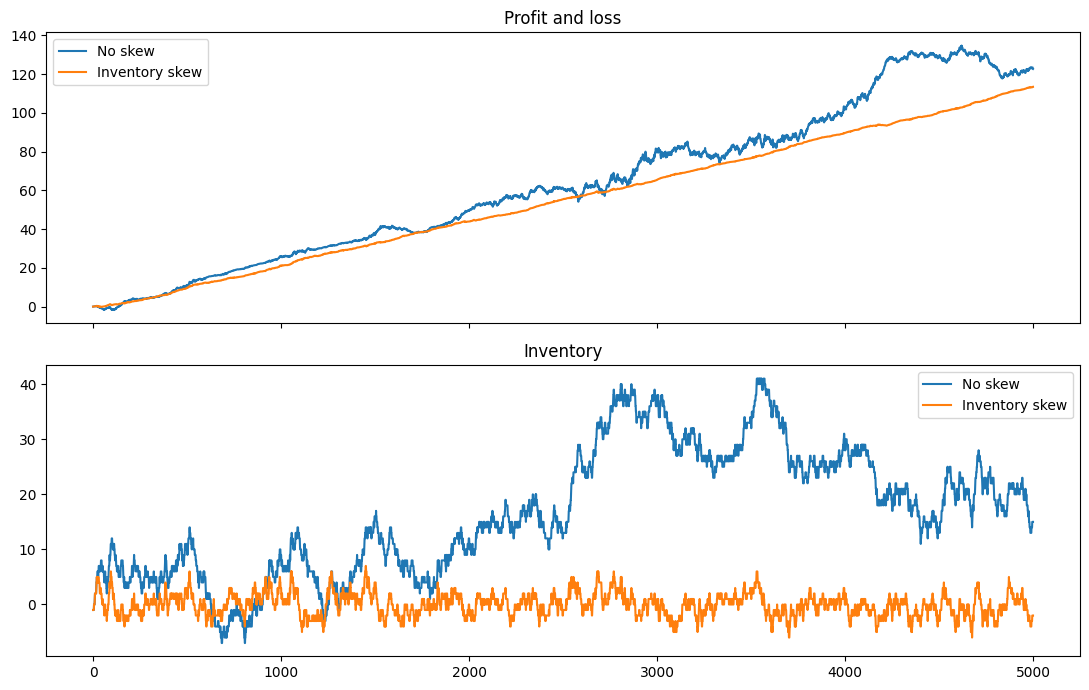

In [2]:
def simulate(skew, seed):
    rng = np.random.default_rng(seed)
    mid, cash, inv = 100.0, 0.0, 0
    pnl, invs = np.empty(STEPS), np.empty(STEPS)
    for t in range(STEPS):
        mid += SIGMA * rng.standard_normal()
        ref = mid - skew * inv
        bid, ask = ref - HALF_SPREAD, ref + HALF_SPREAD
        if inv < MAX_INV and rng.random() < A * np.exp(-K_DECAY * (mid - bid)):
            inv += 1; cash -= bid          # someone sold to us
        if inv > -MAX_INV and rng.random() < A * np.exp(-K_DECAY * (ask - mid)):
            inv -= 1; cash += ask          # someone bought from us
        pnl[t], invs[t] = cash + inv * mid, inv
    return pnl, invs

pnl0, inv0 = simulate(skew=0.0, seed=1)
pnl1, inv1 = simulate(skew=0.005, seed=1)

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(pnl0, label="No skew"); ax[0].plot(pnl1, label="Inventory skew"); ax[0].set_title("Profit and loss"); ax[0].legend()
ax[1].plot(inv0, label="No skew"); ax[1].plot(inv1, label="Inventory skew"); ax[1].set_title("Inventory"); ax[1].legend()
plt.tight_layout(); plt.show()

## Step 3. Many simulated days
One day can be lucky. We run 200 days per setting and compare the **average** and the **risk** (spread of outcomes).

In [3]:
rows = {}
for skew in [0.0, 0.002, 0.005, 0.01]:
    finals, max_inv = [], []
    for seed in range(200):
        p, i = simulate(skew, seed)
        finals.append(p[-1]); max_inv.append(np.abs(i).max())
    finals = np.array(finals)
    rows[f"skew={skew}"] = {"Mean PnL": finals.mean(), "Std PnL": finals.std(),
                            "PnL / Std": finals.mean() / finals.std(),
                            "Worst day": finals.min(), "Avg max |inventory|": np.mean(max_inv)}
pd.DataFrame(rows).T

,Mean PnL,Std PnL,PnL / Std,Worst day,Avg max |inventory|
skew=0.0,115.745744,33.835971,3.420790,-53.394641,41.990
skew=0.002,117.392651,5.695967,20.609783,103.154095,11.585
skew=0.005,115.482255,3.972075,29.073530,105.967826,7.810
skew=0.01,112.492588,3.110037,36.170815,104.158365,5.695


## Step 4. Conclusions
1. **Without skew, inventory risk dominates.** Inventory reached about 42 units on average (close to the 50 limit), and end-of-day PnL varied widely (standard deviation 33.8, worst day −53.4).
2. **A small inventory skew cuts risk sharply at almost no cost.** With skew = 0.002, the standard deviation of PnL fell from 33.8 to 5.7 (about −83%), average PnL stayed similar (117.4 vs 115.7), and even the worst day was profitable (103.2). Average peak inventory fell from 42 to 12 units.
3. **Too much skew gives away profit.** At skew = 0.01, risk fell further (std 3.1) but average PnL dropped to 112.5, because heavily skewed quotes sell too cheaply and buy too dearly. There is a trade-off between inventory risk and expected profit.
4. **Spread trade-off (theory):** fill probability falls exponentially with distance from fair price (A·e^(−kδ)), so a wider spread earns more per trade but gets far fewer fills. An optimal spread balances the two.

**Limitations:** the fair price is a pure random walk (no trends or informed traders); fills are random, not from a real order book; no fees or queue priority. Real market makers also face **adverse selection**: informed traders trade with you right before the price moves against you.

**Further reading:** Avellaneda and Stoikov (2008), "High-frequency trading in a limit order book", the classic model this simulator simplifies.